<a href="https://colab.research.google.com/github/JosiasG-dev/Analisis_de_Algoritmos/blob/main/JOSIAS_ALONZO_Analisis_de_Algoritmos_Laboratorio_de_Algoritmos_Voraces_Avanzados_y_Heur%C3%ADsticas_en_Grafos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Guía de Práctica de Laboratorio 1: Algoritmos Voraces Avanzados y Heurísticas en Grafos

**Asignatura:** Análisis de Algoritmos  
**Institución:** Universidad Autónoma de Tamaulipas (Facultad de Ingeniería Tampico)  
**Unidad / Subtema:** Unidad 3 — Algoritmos Voraces: Mochila Fraccionaria y Heurística del Agente Viajero TSP  

**Objetivos de la Práctica:**
1. **Fundamentar teóricamente el enfoque voraz:** Comprender la Propiedad de Elección Voraz (*Greedy-Choice Property*), la Subestructura Óptima y las demostraciones mediante el Argumento de Intercambio (*Exchange Argument*) a través de consultas guiadas en NotebookLM.
2. **Aplicar criterios de densidad y optimización continua:** Implementar y verificar la exactitud del algoritmo voraz para el Problema de la **Mochila Fraccionaria** mediante el ordenamiento descendente de densidad de valor/peso ($d_i = v_i / w_i$) en tiempo $O(n \log n)$.
3. **Explorar límites heurísticos en problemas NP-difíciles:** Evaluar el comportamiento miope de la **Heurística del Vecino Más Cercano (*Nearest Neighbor*)** aplicada al Problema del Agente Viajero (TSP) en tiempo $O(n^2)$, visualizando la topología de la ruta en Python (`NetworkX`) y midiendo su ejecución nativa en microsegundos con C++ (`-O3`).

---

## Introducción Teórica y Contexto

Un **Algoritmo Voraz** (*Greedy Algorithm*) construye soluciones paso a paso tomando en cada etapa la decisión que parece localmente óptima en ese instante, de manera miope e irrevocable, sin evaluar alternativas futuras ni realizar retroceso (*backtracking*). Para que esta estrategia garantice el óptimo global absoluto, el problema debe satisfacer la **Propiedad de Elección Voraz** y exhibir **Subestructura Óptima**.

En este laboratorio contrastaremos dos escenarios fundamentales:
- **Exactitud en Dominios Continuos (Mochila Fraccionaria):** Cuando es posible dividir los objetos ($0 \le x_i \le 1$), priorizar aquellos con mayor densidad $d_i = v_i / w_i$ llena cada unidad de capacidad con el máximo valor posible, garantizando una solución óptima exacta en $O(n \log n)$.
- **Aproximación Heurística en Combinatoria NP-Difícil (TSP):** En el Problema del Agente Viajero (*Traveling Salesperson Problem*), encontrar el ciclo hamiltoniano de costo mínimo requiere evaluar $(n-1)!/2$ rutas en el peor caso. La **Heurística del Vecino Más Cercano** selecciona iterativamente la ciudad no visitada más próxima en $O(n^2)$, pero su visión local suele obligar al agente a realizar saltos muy costosos al cerrar el recorrido.

---

# Sección 1: Guía de Autoestudio para NotebookLM (Tutor Cognitivo)

Copia y pega directamente las siguientes preguntas (*prompts*) en tu instancia de **NotebookLM**, consultando la bibliografía oficial cargada en el curso (Cormen et al., Baase & Van Gelder, Gómez Fuentes & Cervantes Ojeda [UAM], Lee et al., Univ. del Quindío y Manual INACAP). <u>Tanto las preguntas como las respuestas obtenidas por la IA de NotebookLM deben transcribirse al portafolio de evidencias como notas de clase.</u>

### 1.1 Fundamentos del Paradigma Voraz, Cambio de Monedas y Selección de Actividades

#### Objetivo Temático 1: Comprender los Fundamentos del Paradigma Voraz y la Propiedad de Elección Voraz
* **Nivel Básico (Reconocimiento conceptual):**
  > *"Utilizando el Capítulo V de Gómez Fuentes & Cervantes Ojeda (UAM) y el Capítulo 16 de Cormen et al., define qué es un algoritmo voraz (greedy). Explica cuáles son sus dos características principales: la propiedad de elección voraz y la subestructura óptima."*
* **Nivel Intermedio (Análisis formal):**
  > *"A partir del texto de Lee et al. (Capítulo 3, Sección 3-1) y la Antología UAM (pp. 91-93), explica en qué se diferencia fundamentalmente la toma de decisiones de un algoritmo voraz frente a Backtracking y Ramificación y Poda en cuanto al uso de la pila de memoria y el retroceso."*
* **Nivel Avanzado (Rigor matemático y pruebas de optimalidad):**
  > *"Consulta la Sección 16.2 de Cormen et al. y la Sección 8.1 de Baase & Van Gelder. Explica en qué consiste la técnica de demostración por 'argumento de intercambio' (Exchange Argument) para probar la validez de un algoritmo voraz y por qué es necesaria."*

#### Objetivo Temático 2: Aplicación al Cambio de Monedas y Selección de Actividades
* **Nivel Básico (Reconocimiento de algoritmos):**
  > *"De acuerdo con el manual de la Universidad del Quindío (Sección 2.3.3) y la Antología UAM (p. 94), describe el algoritmo voraz para el Problema del Cambio de Monedas. ¿Qué significa que un sistema monetario sea 'canónico'?"*
* **Nivel Intermedio (Análisis del problema de Selección de Actividades):**
  > *"Con base en la Sección 16.1 de Cormen et al. y la Sección 3-2 de Lee et al., formula el Problema de Selección de Actividades. Justifica por qué seleccionar la actividad con el tiempo de finalización más temprano (f_i) es el criterio voraz correcto frente a elegir la de menor duración o menor tiempo de inicio."*
* **Nivel Avanzado (Análisis comparativo de fallas voraces):**
  > *"A partir del Ejercicio 16.2-4 de Cormen et al. y la Antología UAM (p. 95), demuestra con un contraejemplo numérico (como las denominaciones {1, 3, 4} y valor 6) por qué el algoritmo voraz falla en sistemas de cambio no canónicos y qué paradigma alternativo se requiere."*

---

### 1.2 Mochila Fraccionaria y Heurística del Agente Viajero (TSP)

#### Objetivo Temático 3: Dominar la Mochila Fraccionaria y el Criterio de Densidad
* **Nivel Básico (Reconocimiento conceptual):**
  > *"Con base en el Capítulo V de Gómez Fuentes & Cervantes Ojeda (UAM) y la Sección 16.2 de Cormen et al., formula el Problema de la Mochila Fraccionaria. Explica qué representa la densidad de valor d_i = v_i / w_i y cómo se utiliza para ordenar los objetos."*
* **Nivel Intermedio (Análisis comparativo de fallos):**
  > *"A partir del texto de Cormen et al. (pp. 426-427) y la Antología UAM (pp. 101-102), analiza el ejemplo numérico de una mochila con W=50 kg y objetos (10kg, $60), (20kg, $100), (30kg, $120). Demuestra por qué el algoritmo voraz obtiene el óptimo absoluto en la variante fraccionaria pero produce una solución subóptima en la Mochila 0/1."*
* **Nivel Avanzado (Rigor formal y complejidad):**
  > *"Consultando las lecturas de Baase & Van Gelder (Capítulo 13, Sección 13.8.2) y Lee et al. (Capítulo 3), demuestra la complejidad temporal O(n log n) del algoritmo voraz para la mochila fraccionaria y justifica por qué no es necesario evaluar combinaciones alternativas de objetos."*

#### Objetivo Temático 4: Comprender el Problema del Agente Viajero (TSP) y la Heurística Voraz
* **Nivel Básico (Reconocimiento de problemas NP-difíciles):**
  > *"De acuerdo con la Sección V.5 de la Antología UAM y el Capítulo 9 de Lee et al., define el Problema del Agente Viajero (TSP). ¿Qué es un ciclo hamiltoniano y por qué la búsqueda por fuerza bruta requiere (n-1)! / 2 evaluaciones?"*
* **Nivel Intermedio (Algoritmo del Vecino Más Cercano):**
  > *"A partir del texto de Baase & Van Gelder (Sección 13.6, pp. 580-582) y la Antología UAM (p. 111), describe paso a paso la Heurística del Vecino Más Cercano (Nearest Neighbor) para el TSP. ¿Cuál es su complejidad temporal O(n^2) y cómo selecciona la siguiente ciudad a visitar?"*
* **Nivel Avanzado (Análisis de límites heurísticos):**
  > *"Consulta la Sección 13.6 de Baase & Van Gelder y el manual de INACAP (Sección 5.5). Explica por qué la heurística voraz del vecino más cercano en el TSP puede verse obligada a tomar aristas de costo muy alto al final del recorrido y por qué esto demuestra que el algoritmo no garantiza el óptimo global."*

---

# Sección 2: Laboratorio Práctico en Google Colab — Visualización y Benchmarking

### 2.1 Implementación y Visualización de Grafos en Python (Mochila Fraccionaria y TSP Voraz)

*Instrucciones:* Ejecuta la siguiente celda de código en Google Colab. Este script resuelve la **Mochila Fraccionaria** ordenando por densidad $v_i / w_i$, ejecuta la **Heurística del Vecino Más Cercano** para el TSP e incluye la graficación del grafo de ciudades y la ruta trazada con flechas mediante `NetworkX` y `Matplotlib`.

=== 1. PRUEBA DE LA MOCHILA FRACCIONARIA ===
Capacidad Mochila: 50 kg
Valor Máximo Óptimo Alcanzado: $240.00
Desglose de Selección Voraz (Nombre, Fracción x_i, Peso Tomado, Valor Obtenido):
   -> ('Obj1 (Oro)', 1.0, 10, 60)
   -> ('Obj2 (Plata)', 1.0, 20, 100)
   -> ('Obj3 (Bronce)', 0.67, 20, 80.0)

=== 2. PRUEBA DEL AGENTE VIAJERO (TSP - VECINO MÁS CERCANO) ===
Ruta Voraz Obtenida: CDMX -> Cuernavaca -> Puebla -> Toluca -> Querétaro -> Pachuca -> CDMX
Distancia Total de la Ruta: 31.02 unidades
Tiempo de Ejecución: 0.2351 ms



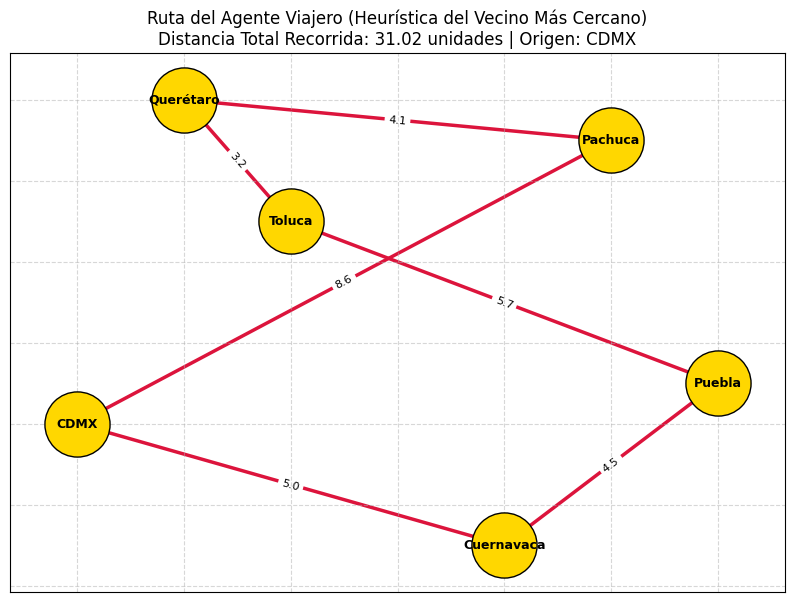

In [1]:
# ==============================================================================
# LABORATORIO UNIDAD 3 - ALGORITMOS VORACES II EN PYTHON
# ==============================================================================
import time
import math
import matplotlib.pyplot as plt
import networkx as nx

# ------------------------------------------------------------------------------
# 1. PROBLEMA DE LA MOCHILA FRACCIONARIA (CRITERIO POR DENSIDAD)
# ------------------------------------------------------------------------------
class ObjetoFraccionario:
    def __init__(self, nombre, peso, valor):
        self.nombre = nombre
        self.peso = peso
        self.valor = valor
        self.densidad = valor / peso

def mochila_fraccionaria_voraz(objetos, capacidad):
    # ORDENAR POR DENSIDAD DESCENDENTE: O(n log n)
    objetos_ordenados = sorted(objetos, key=lambda obj: obj.densidad, reverse=True)

    capacidad_restante = capacidad
    valor_total = 0.0
    solucion_desglose = []

    for obj in objetos_ordenados:
        if capacidad_restante == 0:
            break

        if obj.peso <= capacidad_restante:
            # Tomar objeto entero (x_i = 1.0)
            capacidad_restante -= obj.peso
            valor_total += obj.valor
            solucion_desglose.append((obj.nombre, 1.0, obj.peso, obj.valor))
        else:
            # Tomar fracción del objeto (0 < x_i < 1.0)
            fraccion = capacidad_restante / obj.peso
            valor_fraccional = obj.valor * fraccion
            valor_total += valor_fraccional
            solucion_desglose.append((obj.nombre, round(fraccion, 2), capacidad_restante, valor_fraccional))
            capacidad_restante = 0  # Mochila llena al 100%

    return valor_total, solucion_desglose

# ------------------------------------------------------------------------------
# 2. HEURÍSTICA DEL VECINO MÁS CERCANO PARA EL AGENTE VIAJERO (TSP)
# ------------------------------------------------------------------------------
def calcular_distancia(p1, p2):
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)

def tsp_vecino_mas_cercano(ciudades_pos, origen=None):
    # ciudades_pos: dict de {nombre_ciudad: (x, y)}
    nombres = list(ciudades_pos.keys())
    n = len(nombres)

    visitadas = set()
    ciudad_origen = origen if origen in ciudades_pos else nombres[0]
    ciudad_actual = ciudad_origen
    visitadas.add(ciudad_actual)

    ruta = [ciudad_actual]
    distancia_total = 0.0

    while len(visitadas) < n:
        vecino_mas_cercano = None
        distancia_minima = float('inf')

        for candidata in nombres:
            if candidata not in visitadas:
                dist = calcular_distancia(ciudades_pos[ciudad_actual], ciudades_pos[candidata])
                if dist < distancia_minima:
                    distancia_minima = dist
                    vecino_mas_cercano = candidata

        visitadas.add(vecino_mas_cercano)
        ruta.append(vecino_mas_cercano)
        distancia_total += distancia_minima
        ciudad_actual = vecino_mas_cercano

    # Retorno a la ciudad origen
    dist_retorno = calcular_distancia(ciudades_pos[ciudad_actual], ciudades_pos[ciudad_origen])
    distancia_total += dist_retorno
    ruta.append(ciudad_origen)

    return ruta, distancia_total

# ------------------------------------------------------------------------------
# 3. EJECUCIÓN Y PRUEBAS DEL LABORATORIO
# ------------------------------------------------------------------------------
print("=== 1. PRUEBA DE LA MOCHILA FRACCIONARIA ===")
lista_objetos = [
    ObjetoFraccionario("Obj1 (Oro)", 10, 60),    # Densidad = 6.0
    ObjetoFraccionario("Obj2 (Plata)", 20, 100),  # Densidad = 5.0
    ObjetoFraccionario("Obj3 (Bronce)", 30, 120)  # Densidad = 4.0
]
capacidad_mochila = 50

val_max, desglose_mochila = mochila_fraccionaria_voraz(lista_objetos, capacidad_mochila)
print(f"Capacidad Mochila: {capacidad_mochila} kg")
print(f"Valor Máximo Óptimo Alcanzado: ${val_max:.2f}")
print("Desglose de Selección Voraz (Nombre, Fracción x_i, Peso Tomado, Valor Obtenido):")
for item in desglose_mochila:
    print(f"   -> {item}")
print()

print("=== 2. PRUEBA DEL AGENTE VIAJERO (TSP - VECINO MÁS CERCANO) ===")
# Posiciones 2D de 6 Ciudades
pos_ciudades = {
    'CDMX': (0, 0),
    'Toluca': (2, 5),
    'Puebla': (6, 1),
    'Querétaro': (1, 8),
    'Cuernavaca': (4, -3),
    'Pachuca': (5, 7)
}

t0 = time.time()
ruta_tsp, dist_tsp = tsp_vecino_mas_cercano(pos_ciudades, origen='CDMX')
t_tsp = (time.time() - t0) * 1000

print(f"Ruta Voraz Obtenida: {' -> '.join(ruta_tsp)}")
print(f"Distancia Total de la Ruta: {dist_tsp:.2f} unidades")
print(f"Tiempo de Ejecución: {t_tsp:.4f} ms\n")

# ------------------------------------------------------------------------------
# 4. VISUALIZACIÓN GRÁFICA DEL GRAFO TSP (NETWORKX + MATPLOTLIB)
# ------------------------------------------------------------------------------
G = nx.DiGraph()

# Agregar nodos con coordenadas
for ciudad, pos in pos_ciudades.items():
    G.add_node(ciudad, pos=pos)

# Agregar aristas con dirección de la ruta TSP
aristas_ruta = []
for i in range(len(ruta_tsp) - 1):
    u, v = ruta_tsp[i], ruta_tsp[i+1]
    dist_uv = calcular_distancia(pos_ciudades[u], pos_ciudades[v])
    G.add_edge(u, v, weight=round(dist_uv, 1))
    aristas_ruta.append((u, v))

plt.figure(figsize=(10, 7))
pos_layout = nx.get_node_attributes(G, 'pos')

# Dibujar Nodos (Ciudades)
nx.draw_networkx_nodes(G, pos_layout, node_color='gold', node_size=2200, edgecolors='black')
nx.draw_networkx_labels(G, pos_layout, font_size=9, font_weight='bold')

# Dibujar Flechas de la Ruta Voraz
nx.draw_networkx_edges(G, pos_layout, edgelist=aristas_ruta, edge_color='crimson',
                       width=2.5, arrowstyle='->', arrowsize=20)

# Dibujar Etiquetas de Distancia en las Aristas
labels_aristas = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos_layout, edge_labels=labels_aristas, font_size=8)

plt.title(f"Ruta del Agente Viajero (Heurística del Vecino Más Cercano)\nDistancia Total Recorrida: {dist_tsp:.2f} unidades | Origen: CDMX")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


### 2.2 Implementación Compilable y Estructurada en C++

*Instrucciones:* Ejecuta las siguientes dos celdas en Google Colab para escribir el archivo `laboratorio_voraces_2.cpp`, compilarlo con `g++ -O3` y ejecutar la Mochila Fraccionaria y la Heurística TSP sobre una matriz de distancias midiendo el tiempo de ejecución nativo en microsegundos.

In [2]:
%%writefile laboratorio_voraces_2.cpp
// ==============================================================================
// LABORATORIO UNIDAD 3 - ALGORITMOS VORACES II EN C++
// ==============================================================================
#include <iostream>
#include <vector>
#include <algorithm>
#include <chrono>
#include <cmath>
#include <iomanip>
#include <string>

using namespace std;

// ------------------------------------------------------------------------------
// 1. ESTRUCTURA Y MÉTODOS PARA LA MOCHILA FRACCIONARIA
// ------------------------------------------------------------------------------
struct Objeto {
    string nombre;
    double peso;
    double valor;
    double densidad;
};

bool compararPorDensidad(const Objeto& a, const Objeto& b) {
    return a.densidad > b.densidad; // Orden descendente
}

void resolverMochilaFraccionaria(vector<Objeto> objetos, double capacidad) {
    // Ordenar por densidad: O(n log n)
    sort(objetos.begin(), objetos.end(), compararPorDensidad);

    double capacidadRestante = capacidad;
    double valorTotal = 0.0;

    cout << "=== 1. RESULTADOS DE LA MOCHILA FRACCIONARIA EN C++ ===" << endl;
    cout << fixed << setprecision(2);

    for (const auto& obj : objetos) {
        if (capacidadRestante == 0) break;

        if (obj.peso <= capacidadRestante) {
            capacidadRestante -= obj.peso;
            valorTotal += obj.valor;
            cout << "   -> Tomar entero: " << obj.nombre << " (100% - Peso: "
                 << obj.peso << " kg, Valor: $" << obj.valor << ")" << endl;
        } else {
            double fraccion = capacidadRestante / obj.peso;
            double valFrac = obj.valor * fraccion;
            valorTotal += valFrac;
            cout << "   -> Tomar fraccion: " << obj.nombre << " (" << (fraccion * 100)
                 << "% - Peso: " << capacidadRestante << " kg, Valor: $" << valFrac << ")" << endl;
            capacidadRestante = 0;
        }
    }
    cout << "   -> VALOR MÁXIMO ÓPTIMO TOTAL: $" << valorTotal << "\n" << endl;
}

// ------------------------------------------------------------------------------
// 2. HEURÍSTICA DEL VECINO MÁS CERCANO PARA EL AGENTE VIAJERO (TSP)
// ------------------------------------------------------------------------------
void resolverTSP(const vector<vector<double>>& matrizDistancias, const vector<string>& ciudades) {
    int n = ciudades.size();
    vector<bool> visitadas(n, false);
    vector<int> ruta;

    auto start = chrono::high_resolution_clock::now();

    int actual = 0; // Ciudad origen = 0
    visitadas[actual] = true;
    ruta.push_back(actual);
    double distanciaTotal = 0.0;

    for (int i = 0; i < n - 1; i++) {
        int vecinoMasCercano = -1;
        double distMin = 1e9;

        for (int j = 0; j < n; j++) {
            if (!visitadas[j] && matrizDistancias[actual][j] < distMin) {
                distMin = matrizDistancias[actual][j];
                vecinoMasCercano = j;
            }
        }

        visitadas[vecinoMasCercano] = true;
        ruta.push_back(vecinoMasCercano);
        distanciaTotal += distMin;
        actual = vecinoMasCercano;
    }

    // Regreso al origen
    distanciaTotal += matrizDistancias[actual][0];
    ruta.push_back(0);

    auto end = chrono::high_resolution_clock::now();
    chrono::duration<double, micro> duracion = end - start;

    cout << "=== 2. RESULTADOS DEL AGENTE VIAJERO (TSP VECINO MÁS CERCANO) EN C++ ===" << endl;
    cout << "   -> Ruta Obtenida: ";
    for (size_t k = 0; k < ruta.size(); k++) {
        cout << ciudades[ruta[k]] << (k + 1 < ruta.size() ? " -> " : "");
    }
    cout << "\n   -> Distancia Total Recorrida: " << distanciaTotal << " unidades" << endl;
    cout << "   -> Tiempo de Ejecución C++: " << duracion.count() << " us (microsegundos)\n" << endl;
}

int main() {
    cout << "==========================================================" << endl;
    cout << "   DEMOSTRACIÓN DE ALGORITMOS VORACES II (UNIDAD 3)         " << endl;
    cout << "==========================================================" << endl;

    // Mochila
    vector<Objeto> objetos = {
        {"Objeto 1", 10, 60, 6.0},
        {"Objeto 2", 20, 100, 5.0},
        {"Objeto 3", 30, 120, 4.0}
    };
    resolverMochilaFraccionaria(objetos, 50.0);

    // TSP: Matriz de Distancias 5x5
    vector<string> ciudades = {"CDMX", "Toluca", "Puebla", "Querétaro", "Pachuca"};
    vector<vector<double>> dist = {
        {0, 60, 110, 210, 90},
        {60, 0, 150, 160, 130},
        {110, 150, 0, 270, 140},
        {210, 160, 270, 0, 150},
        {90, 130, 140, 150, 0}
    };

    resolverTSP(dist, ciudades);

    return 0;
}


Writing laboratorio_voraces_2.cpp


In [3]:
!g++ -O3 laboratorio_voraces_2.cpp -o laboratorio_v2 && ./laboratorio_v2

   DEMOSTRACIÓN DE ALGORITMOS VORACES II (UNIDAD 3)         
=== 1. RESULTADOS DE LA MOCHILA FRACCIONARIA EN C++ ===
   -> Tomar entero: Objeto 1 (100% - Peso: 10.00 kg, Valor: $60.00)
   -> Tomar entero: Objeto 2 (100% - Peso: 20.00 kg, Valor: $100.00)
   -> Tomar fraccion: Objeto 3 (66.67% - Peso: 20.00 kg, Valor: $80.00)
   -> VALOR MÁXIMO ÓPTIMO TOTAL: $240.00

=== 2. RESULTADOS DEL AGENTE VIAJERO (TSP VECINO MÁS CERCANO) EN C++ ===
   -> Ruta Obtenida: CDMX -> Toluca -> Pachuca -> Puebla -> Querétaro -> CDMX
   -> Distancia Total Recorrida: 810.00 unidades
   -> Tiempo de Ejecución C++: 3.39 us (microsegundos)



---
# Sección Final: Bitácora de Reporte del Alumno(a)

**Nombre del Alumno(a):** ____Gonzalez Alonzo Josias Nahum___   
 **Matrícula:** 2243330336  
**Grupo:** __4-K___ **Fecha de Entrega:** _27/nov/2026___

---

## Parte I: Inspección y Análisis de Resultados (Python & C++)

### Fase 1: Mochila Fraccionaria y Criterio de Densidad

Completa la tabla de selección obtenida al ejecutar el algoritmo voraz para $W = 50\text{ kg}$:

| Orden de Selección | Objeto | Peso Total ($w_i$) | Valor Total ($v_i$) | Densidad ($d_i = v_i / w_i$) | Fracción Tomada ($x_i$) | Valor Aportado |
| :---: | :--- | :---: | :---: | :---: | :---: | :---: |
| **1** | Obj1 (Oro) | $10\text{ kg}$ | $\$60.00$ | $6.0$ | $1.00$ ($100\%$) | $\$60.00$ |
| **2** | Obj2 (Plata) | $20\text{ kg}$ | $\$100.00$ | $5.0$ | $1.00$ ($100\%$) | $\$100.00$ |
| **3** | Obj3 (Bronce) | $30\text{ kg}$ | $\$120.00$ | $4.0$ | $0.67$ ($2/3$) | $\$80.00$ |

- **Pregunta de Análisis 1:** Explica por qué el paso dominante de la Mochila Fraccionaria tiene complejidad $O(n \log n)$ y por qué una vez ordenados los objetos el ciclo de llenado toma tiempo estrictamente lineal $\Theta(n)$.
  > **Paso dominante $O(n \log n)$:** Para aplicar el criterio voraz es indispensable ordenar previamente los $n$ objetos de mayor a menor densidad ($d_i = v_i / w_i$). Los algoritmos de ordenamiento basados en comparaciones más eficientes (*Timsort* en Python e *Introsort* en C++) tienen una complejidad asintótica de $\Theta(n \log n)$, constituyendo el paso de mayor costo computacional.
  
  **Ciclo de llenado lineal $\Theta(n)$:** Una vez ordenados los elementos, el algoritmo ejecuta un único recorrido secuencial sobre los $n$ objetos realizando únicamente comparaciones y operaciones aritméticas en tiempo constante $O(1)$, por lo que su costo es estrictamente $n \cdot O(1) = \Theta(n)$. Por regla de la suma asintótica, $O(n \log n) + \Theta(n) = O(n \log n)$.

### Fase 2: Inspección Topológica de la Ruta TSP (NetworkX & Matplotlib)

1. **Registro de métricas de ejecución (Origen: `CDMX`):**
* **Secuencia de ciudades visitadas en Python:** `CDMX -> Cuernavaca -> Puebla -> Toluca -> Querétaro -> Pachuca -> CDMX`
* **Distancia total recorrida en Python:** `31.02` unidades | **Tiempo Python:** `0.2351` ms
* **Distancia total recorrida en C++ (Matriz 5x5):** `810.00` unidades | **Tiempo C++:** `3.39` $\mu$s

2. **Pregunta de Análisis 2:** Observa la última arista dibujada en rojo en el grafo de `NetworkX` (el tramo de regreso hacia `CDMX`). Compara su longitud frente a las primeras aristas seleccionadas al inicio del recorrido. ¿Cómo ilustra este tramo final el fenómeno de *miopía voraz*?


    Las primeras decisiones del algoritmo seleccionan aristas muy cortas en la vecindad inmediata (`CDMX -> Cuernavaca` con $5.0$ unidades, `Cuernavaca -> Puebla` con $4.5$ unidades y `Toluca -> Querétaro` con $3.2$ unidades). Sin embargo, el tramo final de retorno `Pachuca -> CDMX` tiene una longitud de **$8.6$ unidades**, siendo la arista más costosa de todo el recorrido y generando un cruce diagonal sobre el segmento `Puebla -> Toluca` ($5.7$ unidades).

Esto ejemplifica la **miopía voraz**: al priorizar en cada paso el vecino más cercano sin considerar la estructura global del grafo, el algoritmo decide ir de `Puebla` hacia `Toluca` ($5.7$) en lugar de subir hacia `Pachuca` ($\approx 6.08$), dejando a `Pachuca` aislada al final y forzando un regreso largo y subóptimo hacia el origen.

---

## Parte II: Desafíos Asíncronos de Experimentación (Nivel Medio)

Resuelve los siguientes dos desafíos modificando o extendiendo las celdas de código de este cuaderno. Incluye el código ejecutado y tus conclusiones en los espacios correspondientes.

### Desafío Asíncrono 1: Sensibilidad al Nodo Inicial en el TSP (Heurística Multi-Arranque)
* **Planteamiento:** La heurística del Vecino Más Cercano ($O(n^2)$) es altamente sensible al vértice elegido como punto de partida. Modifica el script de Python (Sección 2.1) para ejecutar `tsp_vecino_mas_cercano` tomando **cada una de las 6 ciudades** (`CDMX`, `Toluca`, `Puebla`, `Querétaro`, `Cuernavaca`, `Pachuca`) como nodo origen distinto.
* **Entregables del Desafío 1:**
  1. Genera una tabla comparativa con las 6 rutas obtenidas y sus distancias totales.
  2. Identifica cuál ciudad origen produce la ruta más corta y cuál produce la peor ruta, calculando la diferencia porcentual entre ambas.
  3. Indica cuál sería la complejidad temporal asintótica total de ejecutar esta estrategia *Multi-Start Nearest Neighbor* sobre un grafo de $n$ ciudades.
| Ciudad Origen | Ruta Voraz Obtenida | Distancia Total |
| :--- | :--- | :---: |
| **CDMX** | `CDMX -> Cuernavaca -> Puebla -> Toluca -> Querétaro -> Pachuca -> CDMX` | $31.02\text{ u}$ |
| **Toluca** | `Toluca -> Querétaro -> Pachuca -> Puebla -> Cuernavaca -> CDMX -> Toluca` | **$27.62\text{ u}$** |
| **Puebla** | `Puebla -> Cuernavaca -> CDMX -> Toluca -> Querétaro -> Pachuca -> Puebla` | **$27.62\text{ u}$** |
| **Querétaro** | `Querétaro -> Toluca -> Pachuca -> Puebla -> Cuernavaca -> CDMX -> Querétaro` | $28.72\text{ u}$ |
| **Cuernavaca** | `Cuernavaca -> Puebla -> CDMX -> Toluca -> Querétaro -> Pachuca -> Cuernavaca` | $29.66\text{ u}$ |
| **Pachuca** | `Pachuca -> Querétaro -> Toluca -> CDMX -> Cuernavaca -> Puebla -> Pachuca` | **$27.62\text{ u}$** |

**2. Mejor y peor ciudad origen, y diferencia porcentual:**
* **Mejores ciudades origen (ruta más corta):** **Toluca, Puebla y Pachuca** empatan con una distancia mínima de **$27.62$ unidades**, recorriendo el perímetro exterior sin cruces de aristas.
* **Peor ciudad origen (ruta más larga):** **CDMX**, con una distancia de **$31.02$ unidades**.
* **Diferencia porcentual:**
  $$\Delta\% = \left( \frac{31.02 - 27.62}{27.62} \right) \times 100 = \mathbf{12.31\%}$$

**3. Complejidad temporal asintótica total (Multi-Start Nearest Neighbor):**
Ejecutar una vez la heurística del Vecino Más Cercano sobre un grafo completo de $n$ ciudades toma $\Theta(n^2)$. Al repetir este proceso utilizando cada uno de los $n$ vértices como punto de partida, la complejidad temporal total es:
$$T(n) = n \cdot \Theta(n^2) = \mathbf{\Theta(n^3)}$$

**4. Conclusiones del Desafío 1:**
La heurística del vecino más cercano presenta una alta sensibilidad al vértice inicial debido a su naturaleza miope. Implementar la estrategia multi-arranque (*Multi-Start*) mitiga este efecto explorando $n$ puntos de partida distintos y logrando reducir el recorrido en más de un $12\%$ respecto al origen por defecto (`CDMX`), manteniendo un tiempo polinómico cúbico $\Theta(n^3)$ muy inferior al costo factorial $\Theta(n!)$ de la fuerza bruta.
### Desafío Asíncrono 2: Comprobación Empírica de Contraejemplos en Cambio de Monedas No Canónico
* **Planteamiento:** Retomando el Objetivo Temático 2 de la Guía de Autoestudio (Sección 1.1), implementa en una nueva celda de Python la función voraz para el Problema del Cambio de Monedas y evalúa su comportamiento con el sistema monetario irregular $C = \{1, 3, 4\}$ para los montos objetivos $V \in \{6, 8, 10, 12\}$.
* **Entregables del Desafío 2:**
  1. Contrasta el número de monedas entregadas por el algoritmo voraz frente al mínimo real posible en cada caso.
  2. Explica por qué el Argumento de Intercambio (*Exchange Argument*) no puede demostrarse sobre el conjunto $C = \{1, 3, 4\}$.


  > **1. Contraste entre el algoritmo voraz y el mínimo real ($C = \{1, 3, 4\}$):**

| Monto Objetivo ($V$) | Selección Voraz | Cantidad Voraz | Selección Óptima Real | Mínimo Real | ¿Falla el Voraz? |
| :---: | :--- | :---: | :--- | :---: | :---: |
| **$6$** | `[4, 1, 1]` | **$3$ monedas** | `[3, 3]` | **$2$ monedas** | **Sí** ($+1$ moneda) |
| **$8$** | `[4, 4]` | **$2$ monedas** | `[4, 4]` | **$2$ monedas** | No |
| **$10$** | `[4, 4, 1, 1]` | **$4$ monedas** | `[4, 3, 3]` | **$3$ monedas** | **Sí** ($+1$ moneda) |
| **$12$** | `[4, 4, 4]` | **$3$ monedas** | `[4, 4, 4]` | **$3$ monedas** | No |

**2. Explicación sobre el fallo del Argumento de Intercambio (*Exchange Argument*):**
Para demostrar la optimalidad de un algoritmo voraz mediante el *Argumento de Intercambio*, debe cumplirse la **propiedad de elección voraz**: dada cualquier solución óptima $O$, debe ser posible sustituir un subconjunto de monedas menores de $O$ (que sumen la moneda máxima $c_{\max} \le V$) por una sola moneda $c_{\max}$ sin aumentar la cardinalidad de la solución.

En el sistema no canónico $C = \{1, 3, 4\}$, esta propiedad se rompe porque **no existe dominancia aditiva entre las denominaciones**:
* Para $V = 6$, la solución óptima es $O = \{3, 3\}$ ($2$ monedas). Ningún subconjunto de $O$ suma $c_{\max} = 4$, por lo que resulta imposible aplicar un intercambio válido para introducir la moneda de $4$.
* Al forzar la elección voraz de $4$, el residuo restante ($6 - 4 = 2$) no puede cubrirse con monedas de $3$ y obliga a utilizar dos monedas de $1$ (`[4, 1, 1]`), incrementando el total a $3$ monedas y demostrando empíricamente que el enfoque voraz no garantiza el óptimo global en sistemas monetarios irregulares.

### Formato de Entrega / Portafolio de Evidencias
1. Guarda este cuaderno con todas las salidas ejecutadas incluyendo las respuestas a las preguntas y desafíos (`Archivo` -> `Guardar una copia en Drive`).
2. Sube los cambios a tu repositorio de GitHub de la materia bajo el nombre `JUAN PEREZ Analisis de Algoritmos - Laboratorio de Algoritmos Voraces Avanzados y Heurísticas en Grafos.ipynb` usando la integración directa (`Archivo` -> `Guardar una copia en GitHub`).
3. Adjunta en tu entregable de plataforma Moodle el enlace de GitHub junto con las notas transcritas de NotebookLM.